In [1]:

# Phase 07 — Robustness Checks and Decision Framework
# Step 07.04B — Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy import stats
from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep,
)

print("Phase 07 libraries imported successfully.")
print("pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


Phase 07 libraries imported successfully.
pandas version: 3.1.1
NumPy version: 2.5.4


In [2]:

# Step 07.04C — Load the existing provisional dataset

from pathlib import Path

data_path = Path("../data/processed/ab_data_provisional_user_level.csv")

df = pd.read_csv(data_path)

print("Dataset loaded successfully.")
print("Rows:", f"{df.shape[0]:,}")
print("Columns:", df.shape[1])
print("Unique users:", f"{df['user_id'].nunique():,}")

print("\nColumn names:")
print(df.columns.tolist())


Dataset loaded successfully.
Rows: 290,584
Columns: 8
Unique users: 290,584

Column names:
['user_id', 'timestamp', 'group', 'landing_page', 'converted', 'was_repeated_user', 'had_cross_group_assignment', 'page_mismatch']


In [3]:

# Step 07.05A — Verify data-quality flags

quality_flags = [
    "was_repeated_user",
    "had_cross_group_assignment",
    "page_mismatch",
]

print("========== DATA-QUALITY FLAGS ==========")

for flag in quality_flags:
    print(f"\n{flag}")
    print(df[flag].value_counts(dropna=False))
    print("Data type:", df[flag].dtype)


========== DATA-QUALITY FLAGS ==========

was_repeated_user
was_repeated_user
False    286690
True       3894
Name: count, dtype: int64
Data type: bool

had_cross_group_assignment
had_cross_group_assignment
False    288689
True       1895
Name: count, dtype: int64
Data type: bool

page_mismatch
page_mismatch
False    288635
True       1949
Name: count, dtype: int64
Data type: bool


In [4]:

# Step 07.05B — Create page-mismatch sensitivity population

df_no_mismatch = df.loc[~df["page_mismatch"]].copy()

print("========== SENSITIVITY POPULATION ==========")

print("Primary population:", f"{len(df):,}")
print("Excluded mismatched users:", f"{df['page_mismatch'].sum():,}")
print("Sensitivity population:", f"{len(df_no_mismatch):,}")

print("\nGroup counts:")
print(df_no_mismatch["group"].value_counts())

print("\nUnique users:", f"{df_no_mismatch['user_id'].nunique():,}")

assert df_no_mismatch["user_id"].is_unique
assert not df_no_mismatch["page_mismatch"].any()

print("\nSensitivity population validation passed.")


========== SENSITIVITY POPULATION ==========
Primary population: 290,584
Excluded mismatched users: 1,949
Sensitivity population: 288,635

Group counts:
group
control      144319
treatment    144316
Name: count, dtype: int64

Unique users: 288,635

Sensitivity population validation passed.


In [5]:

# Step 07.05C — Sensitivity conversion rates

sensitivity_summary = (
    df_no_mismatch
    .groupby("group")["converted"]
    .agg(users="count", conversions="sum", conversion_rate="mean")
)

print("========== SENSITIVITY CONVERSION RATES ==========")
print(sensitivity_summary.to_string())

control_rate = sensitivity_summary.loc["control", "conversion_rate"]
treatment_rate = sensitivity_summary.loc["treatment", "conversion_rate"]

sensitivity_effect_pp = (treatment_rate - control_rate) * 100

primary_effect_pp = (
    df.loc[df["group"] == "treatment", "converted"].mean()
    - df.loc[df["group"] == "control", "converted"].mean()
) * 100

print("\n========== EFFECT COMPARISON ==========")
print(f"Primary effect: {primary_effect_pp:+.4f} percentage points")
print(f"Sensitivity effect: {sensitivity_effect_pp:+.4f} percentage points")
print(f"Change in estimate: {sensitivity_effect_pp - primary_effect_pp:+.4f} percentage points")


========== SENSITIVITY CONVERSION RATES ==========
            users  conversions  conversion_rate
group                                          
control    144319        17375         0.120393
treatment  144316        17130         0.118698

========== EFFECT COMPARISON ==========
Primary effect: -0.1587 percentage points
Sensitivity effect: -0.1695 percentage points
Change in estimate: -0.0109 percentage points


In [6]:

# Step 07.05D — Sensitivity statistical test and CI

control_conversions = int(sensitivity_summary.loc["control", "conversions"])
treatment_conversions = int(sensitivity_summary.loc["treatment", "conversions"])

control_users = int(sensitivity_summary.loc["control", "users"])
treatment_users = int(sensitivity_summary.loc["treatment", "users"])

# Two-sided two-proportion z-test
z_stat, p_value = proportions_ztest(
    count=[treatment_conversions, control_conversions],
    nobs=[treatment_users, control_users],
    alternative="two-sided"
)

# Newcombe 95% confidence interval
ci_low, ci_high = confint_proportions_2indep(
    count1=treatment_conversions,
    nobs1=treatment_users,
    count2=control_conversions,
    nobs2=control_users,
    compare="diff",
    method="newcomb",
    alpha=0.05
)

print("========== SENSITIVITY STATISTICAL RESULTS ==========")
print(f"Z-statistic: {z_stat:.6f}")
print(f"P-value: {p_value:.6f}")
print(f"95% CI: [{ci_low * 100:+.4f}, {ci_high * 100:+.4f}] pp")

print("\nStatistically significant at alpha = 0.05:", p_value < 0.05)


========== SENSITIVITY STATISTICAL RESULTS ==========
Z-statistic: -1.403574
P-value: 0.160446
95% CI: [-0.4062, +0.0672] pp

Statistically significant at alpha = 0.05: False


In [7]:

# Step 07.06A — Exclude cross-group users

df_no_cross_group = df.loc[
    ~df["had_cross_group_assignment"]
].copy()

print("========== CROSS-GROUP SENSITIVITY POPULATION ==========")

print("Primary population:", f"{len(df):,}")

print(
    "Excluded cross-group users:",
    f"{df['had_cross_group_assignment'].sum():,}"
)

print(
    "Sensitivity population:",
    f"{len(df_no_cross_group):,}"
)

print("\nGroup counts:")
print(df_no_cross_group["group"].value_counts())

print("\nUnique users:", f"{df_no_cross_group['user_id'].nunique():,}")

assert df_no_cross_group["user_id"].is_unique
assert not df_no_cross_group["had_cross_group_assignment"].any()

print("\nCross-group sensitivity validation passed.")


========== CROSS-GROUP SENSITIVITY POPULATION ==========
Primary population: 290,584
Excluded cross-group users: 1,895
Sensitivity population: 288,689

Group counts:
group
treatment    144389
control      144300
Name: count, dtype: int64

Unique users: 288,689

Cross-group sensitivity validation passed.


In [8]:

# Step 07.06B — Cross-group sensitivity conversion rates

cross_group_summary = (
    df_no_cross_group
    .groupby("group")["converted"]
    .agg(
        users="count",
        conversions="sum",
        conversion_rate="mean"
    )
)

print("========== CROSS-GROUP SENSITIVITY RATES ==========")
print(cross_group_summary.to_string())

control_rate_cross = cross_group_summary.loc[
    "control", "conversion_rate"
]

treatment_rate_cross = cross_group_summary.loc[
    "treatment", "conversion_rate"
]

cross_group_effect_pp = (
    treatment_rate_cross - control_rate_cross
) * 100

print("\n========== EFFECT COMPARISON ==========")

print(f"Primary effect: {primary_effect_pp:+.4f} pp")
print(f"Cross-group sensitivity effect: {cross_group_effect_pp:+.4f} pp")

print(
    f"Change from primary: "
    f"{cross_group_effect_pp - primary_effect_pp:+.4f} pp"
)


========== CROSS-GROUP SENSITIVITY RATES ==========
            users  conversions  conversion_rate
group                                          
control    144300        17374         0.120402
treatment  144389        17149         0.118769

========== EFFECT COMPARISON ==========
Primary effect: -0.1587 pp
Cross-group sensitivity effect: -0.1633 pp
Change from primary: -0.0046 pp


In [9]:

# Step 07.06C — Cross-group sensitivity statistical test

cross_control_conversions = int(
    cross_group_summary.loc["control", "conversions"]
)

cross_treatment_conversions = int(
    cross_group_summary.loc["treatment", "conversions"]
)

cross_control_users = int(
    cross_group_summary.loc["control", "users"]
)

cross_treatment_users = int(
    cross_group_summary.loc["treatment", "users"]
)

# Two-sided two-proportion z-test
cross_z_stat, cross_p_value = proportions_ztest(
    count=[
        cross_treatment_conversions,
        cross_control_conversions
    ],
    nobs=[
        cross_treatment_users,
        cross_control_users
    ],
    alternative="two-sided"
)

# Newcombe 95% confidence interval
cross_ci_low, cross_ci_high = confint_proportions_2indep(
    count1=cross_treatment_conversions,
    nobs1=cross_treatment_users,
    count2=cross_control_conversions,
    nobs2=cross_control_users,
    compare="diff",
    method="newcomb",
    alpha=0.05
)

print("========== CROSS-GROUP SENSITIVITY RESULTS ==========")

print(f"Z-statistic: {cross_z_stat:.6f}")
print(f"P-value: {cross_p_value:.6f}")

print(
    f"95% CI: "
    f"[{cross_ci_low * 100:+.4f}, "
    f"{cross_ci_high * 100:+.4f}] pp"
)

print(
    "\nStatistically significant at alpha = 0.05:",
    cross_p_value < 0.05
)


========== CROSS-GROUP SENSITIVITY RESULTS ==========
Z-statistic: -1.351627
P-value: 0.176495
95% CI: [-0.4000, +0.0735] pp

Statistically significant at alpha = 0.05: False


In [10]:

# Step 07.07A — Exclude all repeated users

df_no_repeated = df.loc[
    ~df["was_repeated_user"]
].copy()

print("========== REPEATED-USER SENSITIVITY POPULATION ==========")

print("Primary population:", f"{len(df):,}")

print(
    "Excluded repeated users:",
    f"{df['was_repeated_user'].sum():,}"
)

print(
    "Sensitivity population:",
    f"{len(df_no_repeated):,}"
)

print("\nGroup counts:")
print(df_no_repeated["group"].value_counts())

print(
    "\nUnique users:",
    f"{df_no_repeated['user_id'].nunique():,}"
)

assert df_no_repeated["user_id"].is_unique
assert not df_no_repeated["was_repeated_user"].any()

print("\nRepeated-user sensitivity validation passed.")


========== REPEATED-USER SENSITIVITY POPULATION ==========
Primary population: 290,584
Excluded repeated users: 3,894
Sensitivity population: 286,690

Group counts:
group
treatment    143397
control      143293
Name: count, dtype: int64

Unique users: 286,690

Repeated-user sensitivity validation passed.


In [11]:

# Step 07.07B — Repeated-user sensitivity conversion rates

repeated_summary = (
    df_no_repeated
    .groupby("group")["converted"]
    .agg(
        users="count",
        conversions="sum",
        conversion_rate="mean"
    )
)

print("========== REPEATED-USER SENSITIVITY RATES ==========")
print(repeated_summary.to_string())

repeated_control_rate = repeated_summary.loc[
    "control", "conversion_rate"
]

repeated_treatment_rate = repeated_summary.loc[
    "treatment", "conversion_rate"
]

repeated_effect_pp = (
    repeated_treatment_rate - repeated_control_rate
) * 100

print("\n========== EFFECT COMPARISON ==========")

print(f"Primary effect: {primary_effect_pp:+.4f} pp")

print(
    f"Repeated-user sensitivity effect: "
    f"{repeated_effect_pp:+.4f} pp"
)

print(
    f"Change from primary: "
    f"{repeated_effect_pp - primary_effect_pp:+.4f} pp"
)


========== REPEATED-USER SENSITIVITY RATES ==========
            users  conversions  conversion_rate
group                                          
control    143293        17220         0.120173
treatment  143397        17025         0.118726

========== EFFECT COMPARISON ==========
Primary effect: -0.1587 pp
Repeated-user sensitivity effect: -0.1447 pp
Change from primary: +0.0140 pp


In [12]:

# Step 07.07C — Repeated-user sensitivity statistical test

repeated_control_conversions = int(
    repeated_summary.loc["control", "conversions"]
)

repeated_treatment_conversions = int(
    repeated_summary.loc["treatment", "conversions"]
)

repeated_control_users = int(
    repeated_summary.loc["control", "users"]
)

repeated_treatment_users = int(
    repeated_summary.loc["treatment", "users"]
)

# Two-sided two-proportion z-test
repeated_z_stat, repeated_p_value = proportions_ztest(
    count=[
        repeated_treatment_conversions,
        repeated_control_conversions
    ],
    nobs=[
        repeated_treatment_users,
        repeated_control_users
    ],
    alternative="two-sided"
)

# Newcombe 95% confidence interval
repeated_ci_low, repeated_ci_high = confint_proportions_2indep(
    count1=repeated_treatment_conversions,
    nobs1=repeated_treatment_users,
    count2=repeated_control_conversions,
    nobs2=repeated_control_users,
    compare="diff",
    method="newcomb",
    alpha=0.05
)

print("========== REPEATED-USER SENSITIVITY RESULTS ==========")

print(f"Z-statistic: {repeated_z_stat:.6f}")
print(f"P-value: {repeated_p_value:.6f}")

print(
    f"95% CI: "
    f"[{repeated_ci_low * 100:+.4f}, "
    f"{repeated_ci_high * 100:+.4f}] pp"
)

print(
    "\nStatistically significant at alpha = 0.05:",
    repeated_p_value < 0.05
)


========== REPEATED-USER SENSITIVITY RESULTS ==========
Z-statistic: -1.194485
P-value: 0.232288
95% CI: [-0.3821, +0.0927] pp

Statistically significant at alpha = 0.05: False


In [13]:

# Step 07.08A — Consolidated robustness comparison table

robustness_comparison = pd.DataFrame([
    {
        "Analysis": "Primary",
        "Users": len(df),
        "Effect_pp": primary_effect_pp,
        "P_value": 0.187589,
        "CI_lower_pp": -0.3947,
        "CI_upper_pp": 0.0773,
    },
    {
        "Analysis": "Exclude page mismatches",
        "Users": len(df_no_mismatch),
        "Effect_pp": sensitivity_effect_pp,
        "P_value": p_value,
        "CI_lower_pp": ci_low * 100,
        "CI_upper_pp": ci_high * 100,
    },
    {
        "Analysis": "Exclude cross-group users",
        "Users": len(df_no_cross_group),
        "Effect_pp": cross_group_effect_pp,
        "P_value": cross_p_value,
        "CI_lower_pp": cross_ci_low * 100,
        "CI_upper_pp": cross_ci_high * 100,
    },
    {
        "Analysis": "Exclude repeated users",
        "Users": len(df_no_repeated),
        "Effect_pp": repeated_effect_pp,
        "P_value": repeated_p_value,
        "CI_lower_pp": repeated_ci_low * 100,
        "CI_upper_pp": repeated_ci_high * 100,
    },
])

robustness_comparison["Significant_0_05"] = (
    robustness_comparison["P_value"] < 0.05
)

print("========== ROBUSTNESS COMPARISON ==========")

print(
    robustness_comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


========== ROBUSTNESS COMPARISON ==========
                 Analysis  Users  Effect_pp  P_value  CI_lower_pp  CI_upper_pp  Significant_0_05
                  Primary 290584  -0.158661 0.187589    -0.394700     0.077300             False
  Exclude page mismatches 288635  -0.169516 0.160446    -0.406236     0.067201             False
Exclude cross-group users 288689  -0.163251 0.176495    -0.399983     0.073479             False
   Exclude repeated users 286690  -0.144702 0.232288    -0.382142     0.092735             False


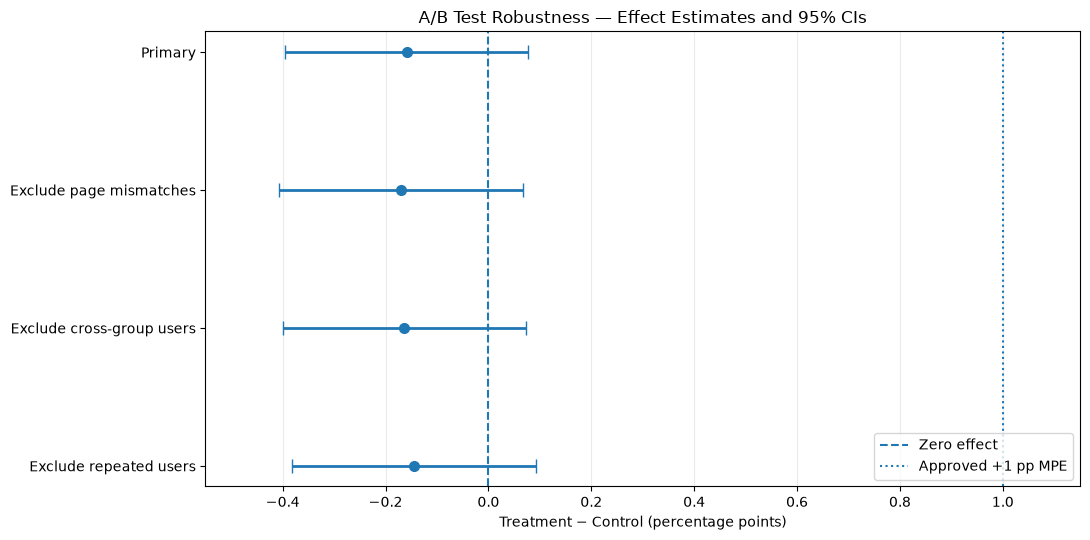

In [14]:

# Step 07.08B — Robustness confidence interval forest plot

plot_data = robustness_comparison.iloc[::-1].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11, 5.5))

y_positions = np.arange(len(plot_data))

effects = plot_data["Effect_pp"].to_numpy()

lower_errors = effects - plot_data["CI_lower_pp"].to_numpy()
upper_errors = plot_data["CI_upper_pp"].to_numpy() - effects

ax.errorbar(
    effects,
    y_positions,
    xerr=[lower_errors, upper_errors],
    fmt="o",
    capsize=5,
    markersize=7,
    linewidth=2
)

# Zero = no conversion-rate difference
ax.axvline(0, linestyle="--", linewidth=1.5, label="Zero effect")

# Approved practical improvement threshold
ax.axvline(
    1.0,
    linestyle=":",
    linewidth=1.5,
    label="Approved +1 pp MPE"
)

ax.set_yticks(y_positions)
ax.set_yticklabels(plot_data["Analysis"])

ax.set_xlabel("Treatment − Control (percentage points)")
ax.set_title("A/B Test Robustness — Effect Estimates and 95% CIs")

ax.grid(axis="x", alpha=0.25)
ax.legend(loc="lower right")

# Include the approved MPE without compressing the effect estimates too much
ax.set_xlim(-0.55, 1.15)

plt.tight_layout()
plt.show()


In [15]:

# Step 07.09A — Practical significance assessment

approved_mpe_pp = 1.0

def classify_mpe_evidence(row):
    lower = row["CI_lower_pp"]
    upper = row["CI_upper_pp"]

    if lower > approved_mpe_pp:
        return "Supports +1 pp improvement"
    elif upper < approved_mpe_pp:
        return "Does not support +1 pp improvement"
    else:
        return "Inconclusive relative to +1 pp MPE"

robustness_comparison["MPE_assessment"] = (
    robustness_comparison.apply(classify_mpe_evidence, axis=1)
)

print("========== PRACTICAL SIGNIFICANCE ASSESSMENT ==========")

print(
    robustness_comparison[
        [
            "Analysis",
            "Effect_pp",
            "CI_lower_pp",
            "CI_upper_pp",
            "MPE_assessment"
        ]
    ].to_string(index=False)
)


========== PRACTICAL SIGNIFICANCE ASSESSMENT ==========
                 Analysis  Effect_pp  CI_lower_pp  CI_upper_pp                     MPE_assessment
                  Primary  -0.158661    -0.394700     0.077300 Does not support +1 pp improvement
  Exclude page mismatches  -0.169516    -0.406236     0.067201 Does not support +1 pp improvement
Exclude cross-group users  -0.163251    -0.399983     0.073479 Does not support +1 pp improvement
   Exclude repeated users  -0.144702    -0.382142     0.092735 Does not support +1 pp improvement


In [16]:

# Step 07.10A — Apply approved decision framework

def classify_decision(row):
    lower = row["CI_lower_pp"]
    upper = row["CI_upper_pp"]

    if lower > approved_mpe_pp:
        return "Ship — conditional"

    elif upper < approved_mpe_pp:
        return "Retain original — conditional"

    else:
        return "Inconclusive — follow-up required"


robustness_comparison["Numerical_decision"] = (
    robustness_comparison.apply(
        classify_decision,
        axis=1
    )
)

print("========== NUMERICAL DECISION FRAMEWORK ==========")

print(
    robustness_comparison[
        [
            "Analysis",
            "CI_lower_pp",
            "CI_upper_pp",
            "Numerical_decision"
        ]
    ].to_string(index=False)
)

print(
    "\nIMPORTANT: These are numerical classifications only."
    "\nFinal recommendations require data-quality review."
)


========== NUMERICAL DECISION FRAMEWORK ==========
                 Analysis  CI_lower_pp  CI_upper_pp            Numerical_decision
                  Primary    -0.394700     0.077300 Retain original — conditional
  Exclude page mismatches    -0.406236     0.067201 Retain original — conditional
Exclude cross-group users    -0.399983     0.073479 Retain original — conditional
   Exclude repeated users    -0.382142     0.092735 Retain original — conditional

IMPORTANT: These are numerical classifications only.
Final recommendations require data-quality review.



## Step 07.10B — Decision Limitations and Evidence Quality

### 1. Assignment provenance

The original randomized assignment log is unavailable.

The analytical dataset retains each user's earliest recorded observation as a provisional assignment proxy. Therefore, original randomization integrity cannot be conclusively verified.

### 2. Data-quality sensitivity

Three secondary sensitivity analyses were conducted:

- Excluding retained group/page mismatches.
- Excluding users with cross-group assignment histories.
- Excluding users with repeated observations.

All three produced results consistent with the primary analysis. However, excluding flagged users may introduce selection bias and does not reconstruct the true original assignment.

### 3. Statistical uncertainty

The primary two-sided test was not statistically significant at alpha = 0.05.

The primary 95% confidence interval includes zero. Therefore, the experiment does not establish that the redesign improves or harms conversion.

Non-significance does not establish equivalence.

### 4. Practical significance

The approved minimum practically important improvement is +1 percentage point.

The upper confidence bounds of all four analyses are below +1 percentage point.

The available numerical evidence does not support an improvement reaching the approved MPE, conditional on the analysis assumptions.

### 5. Business and financial limitations

The dataset does not contain verified revenue per conversion, contribution profit, implementation costs, or incremental operating costs.

Therefore, actual financial gains, losses, and rollout profitability cannot be established.

### 6. Decision implication

The numerical decision framework supports retaining the original landing page.

The final recommendation must remain conditional on data-quality credibility, provisional assignment limitations, and operational considerations.

A future experiment with independently verifiable user assignments would provide stronger evidence for a rollout decision.



## Step 07.10C — Product Manager Recommendation

### Recommendation: Retain the Original Landing Page (Conditional)

**Decision:** Do not roll out the redesigned landing page based on the available evidence. Retain the existing landing page while acknowledging the experiment's data-quality and assignment-provenance limitations.

### Supporting Evidence

1. **Primary analysis:** The observed treatment effect was approximately -0.1587 percentage points, with a two-sided p-value of 0.187589.

2. **Statistical uncertainty:** The primary Newcombe 95% confidence interval was approximately [-0.3947, +0.0773] percentage points and included zero.

3. **Robustness:** Three secondary exclusion-based sensitivity analyses produced similar negative point estimates and non-significant p-values.

4. **Practical significance:** All four confidence intervals had upper bounds below the approved +1 percentage-point minimum practically important improvement.

5. **Data quality:** Original randomized assignments could not be independently verified. The retained earliest-observation assignment is provisional.

### Business Interpretation

The available analysis does not demonstrate that the redesigned landing page improves conversion.

Under the approved numerical decision framework, the evidence supports retaining the original landing page rather than shipping the redesign.

However, this conclusion is conditional on the credibility of the recorded assignments and analytical assumptions.

The findings do not establish equivalence or prove that the redesign is harmful.

### Recommended Next Actions

- Retain the original landing page for the current rollout decision.
- Investigate whether original randomization and exposure logs can be recovered.
- Review experiment instrumentation and assignment consistency.
- If the redesign remains strategically important, conduct a new properly randomized experiment with independently verifiable assignments.
- Use prospective sample-size planning and the approved practical-improvement threshold when designing the follow-up experiment.
- Evaluate verified business value and implementation costs before any future rollout.

### Final Decision Status

**Retain original — conditional on data-quality credibility and operational review.**

This recommendation is based on the approved experiment decision framework, not on statistical significance alone.
